<a href="https://colab.research.google.com/github/cmpquilatan21/SBA_FinalCaseStudy_Team3_2026/blob/main/ML_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import io
from google.colab import files

uploaded = files.upload()  # click "Choose Files" and pick SBAnational_cleaned.csv
filename = list(uploaded.keys())[0]  # grabs the actual uploaded name, even if Colab renames it
df = pd.read_csv(io.BytesIO(uploaded[filename]), parse_dates=["ApprovalDate", "DisbursementDate"])  # keeps dates as real dates
print("Loaded:", filename)
print("Shape:", df.shape)  # (896361, 22)
print("Default rate:", round(df["Default"].mean(), 4))  # 0.175

Saving SBAnational_cleaned.csv to SBAnational_cleaned.csv
Loaded: SBAnational_cleaned.csv
Shape: (896361, 22)
Default rate: 0.175


In [ ]:
import os, io, urllib.request
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
from fontTools.ttLib import TTFont

# --- Slide colors (sampled from your deck) ---
BLACK = "#000000"
PURPLE = "#AB4FF5"    # purple glow / bands
MAGENTA = "#D20973"   # pink-magenta bands
VIOLET = "#C125A8"    # middle of the gradient
LAVENDER = "#AD9AEB"  # "78%" / big-number purple
LILAC = "#E7DDF6"     # light card background
CORAL = "#FF6234"     # "Any questions?" orange
WHITE = "#FFFFFF"
GREY = "#8A8A8A"

# --- Download slide fonts (Jost for titles, Figtree for text) ---
def get_font(family, weight):
    path = f"{family.capitalize()}-{weight}.ttf"
    if not os.path.exists(path):  # only download once
        url = f"https://cdn.jsdelivr.net/npm/@fontsource/{family}@5.3.0/files/{family}-latin-{weight}-normal.woff"
        f = TTFont(io.BytesIO(urllib.request.urlopen(url).read()))
        f.flavor = None  # convert web font -> normal .ttf
        f.save(path)
    fm.fontManager.addfont(path)
    return fm.FontProperties(fname=path).get_name()

try:
    BODY = get_font("figtree", 400)   # body text
    BOLD = get_font("figtree", 600)   # big numbers
    TITLE = get_font("jost", 400)     # titles
except Exception as e:
    print("Font download failed, using default font:", e)
    BODY = BOLD = TITLE = "DejaVu Sans"

plt.rcParams.update({
    "figure.facecolor": BLACK, "axes.facecolor": BLACK, "savefig.facecolor": BLACK,
    "font.family": [BODY, "DejaVu Sans"], "font.size": 13,
    "text.color": WHITE, "axes.labelcolor": WHITE, "xtick.color": WHITE, "ytick.color": WHITE,
    "axes.edgecolor": "#444444", "axes.titlecolor": WHITE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#2A2A2A", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def title(ax, text, sub=None):
    ax.set_title(text, loc="left", fontfamily=TITLE, fontsize=20, pad=28 if sub else 14)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=12, color=LAVENDER, va="bottom")

os.makedirs("charts", exist_ok=True)  # all slide images get saved here
print("Fonts:", TITLE, "/", BODY)

Fonts: Jost / Figtree


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

features_num = ["Term", "NoEmp", "log_GrAppv", "SBA_Portion"]  # numeric inputs
features_bin = ["Recession", "Franchise", "StateMatch"]  # already 0/1 (RealEstate left out: it is built from Term, so both together confuse the weights)
features_cat = ["NewExist", "UrbanRural", "LowDoc", "RevLineCr", "NAICS_Sector", "State"]  # categories -> dummy columns

X = pd.get_dummies(df[features_num + features_bin + features_cat], columns=features_cat, drop_first=True, dtype=int)
y = df["Default"]  # 1 = default (positive class), 0 = paid in full

X_train, X_test, y_train, y_test, d_train, d_test = train_test_split(
    X, y, df["DisbursementGross"], test_size=0.3, random_state=42, stratify=y)  # 70/30 split, same default rate in both

scaler = StandardScaler()
X_train[features_num] = scaler.fit_transform(X_train[features_num])  # put numbers on the same scale
X_test[features_num] = scaler.transform(X_test[features_num])  # use training scale on test (no peeking)

print("Training loans:", f"{len(X_train):,}", "| Test loans:", f"{len(X_test):,}")  # 627,452 | 268,909
print("Model inputs:", X.shape[1])
print("Default rate train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Training loans: 627,452 | Test loans: 268,909
Model inputs: 86
Default rate train / test: 0.175 / 0.175


In [ ]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")  # untrained: always guesses the most common outcome
dummy.fit(X_train, y_train)
print("Dummy always predicts:", dummy.predict(X_test[:1])[0], "(0 = Paid in Full)")

Dummy always predicts: 0 (0 = Paid in Full)


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)  # baseline logistic regression
model.fit(X_train, y_train)  # learns the risk weight of each input

p_train = model.predict_proba(X_train)[:, 1]  # probability of default, training loans
p_test = model.predict_proba(X_test)[:, 1]    # probability of default, test loans
CUTOFF = 1 / 6  # break-even: 0.05 / (0.05 + 0.25), from the 5-to-1 cost ratio
print("Average predicted default risk (test):", round(p_test.mean(), 3))

Average predicted default risk (test): 0.175


,Model,Data,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy (always 'paid'),Train,0.825,0.000,0.000,0.000,0.500
1,Dummy (always 'paid'),Test,0.825,0.000,0.000,0.000,0.500
2,Logistic regression 50% cutoff,Train,0.865,0.754,0.336,0.465,0.853
3,Logistic regression 50% cutoff,Test,0.866,0.756,0.341,0.470,0.853
4,Logistic regression 16.7% cutoff,Train,0.720,0.368,0.839,0.512,0.853
5,Logistic regression 16.7% cutoff,Test,0.719,0.367,0.839,0.511,0.853


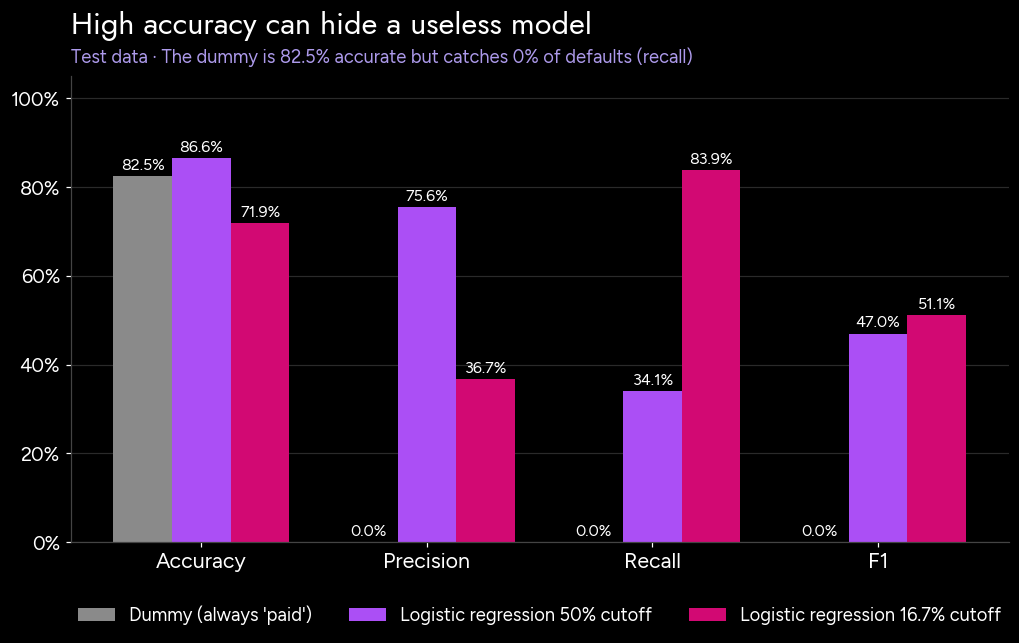

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {  # name: (train probabilities, test probabilities, cutoff)
    "Dummy\n(always 'paid')": (dummy.predict_proba(X_train)[:, 1], dummy.predict_proba(X_test)[:, 1], 0.5),
    "Logistic regression\n50% cutoff": (p_train, p_test, 0.5),
    "Logistic regression\n16.7% cutoff": (p_train, p_test, CUTOFF),
}

rows = []
for name, (ptr, pte, cut) in models.items():
    for split, yt, p in [("Train", y_train, ptr), ("Test", y_test, pte)]:
        pred = (p >= cut).astype(int)
        rows.append({"Model": name.replace("\n", " "), "Data": split,
                     "Accuracy": accuracy_score(yt, pred), "Precision": precision_score(yt, pred, zero_division=0),
                     "Recall": recall_score(yt, pred), "F1": f1_score(yt, pred), "ROC-AUC": roc_auc_score(yt, p)})
results = pd.DataFrame(rows).round(3)
display(results)  # train vs test for every model (check for overfitting)

# --- Chart: accuracy vs. the metrics that matter (test data) ---
test = results[results["Data"] == "Test"].reset_index(drop=True)
metrics = ["Accuracy", "Precision", "Recall", "F1"]
colors = [GREY, PURPLE, MAGENTA]
fig, ax = plt.subplots(figsize=(11, 5.5))
w = 0.26
x = np.arange(len(metrics))
for i, (name, c) in enumerate(zip(models.keys(), colors)):
    vals = test.loc[i, metrics].values
    bars = ax.bar(x + (i - 1) * w, vals, w, color=c, label=name.replace("\n", " "))
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.1%}", ha="center", fontsize=10.5)
ax.set_xticks(x, metrics, fontsize=14)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=12)
title(ax, "High accuracy can hide a useless model", "Test data · The dummy is 82.5% accurate but catches 0% of defaults (recall)")
plt.savefig("charts/1_model_comparison.png")
plt.show()

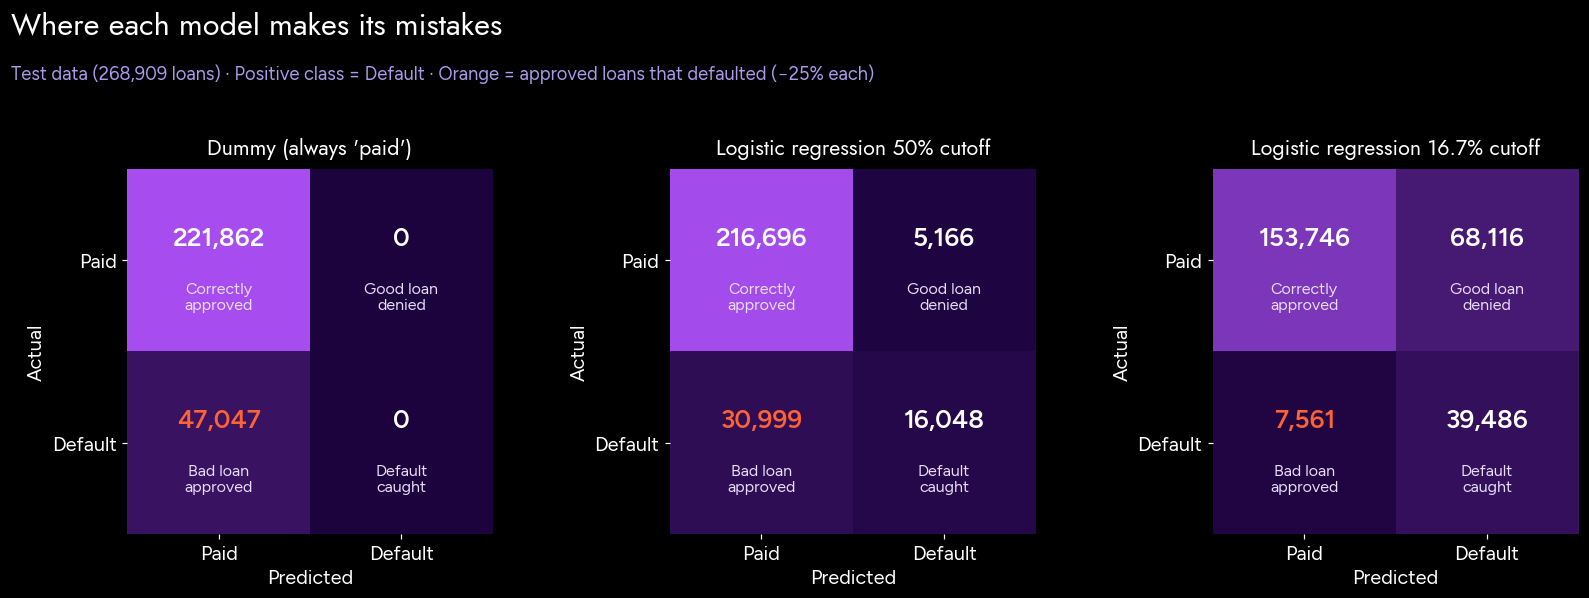

In [ ]:
from sklearn.metrics import confusion_matrix

cmap = LinearSegmentedColormap.from_list("slides", ["#1C033D", PURPLE])
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, (name, (_, pte, cut)) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, (pte >= cut).astype(int))
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=len(y_test) * 0.85)
    labels = [["Correctly\napproved", "Good loan\ndenied"], ["Bad loan\napproved", "Default\ncaught"]]
    for i in range(2):
        for j in range(2):
            color = CORAL if (i, j) == (1, 0) else WHITE  # highlight the expensive mistake
            ax.text(j, i - 0.12, f"{cm[i, j]:,}", ha="center", va="center", fontsize=17, color=color, fontfamily=BOLD)
            ax.text(j, i + 0.2, labels[i][j], ha="center", va="center", fontsize=10.5, color=LILAC)
    ax.set_xticks([0, 1], ["Paid", "Default"])
    ax.set_yticks([0, 1], ["Paid", "Default"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(name.replace("\n", " "), fontfamily=TITLE, fontsize=14, pad=10)
fig.suptitle("Where each model makes its mistakes", x=0.02, y=0.99, ha="left", fontfamily=TITLE, fontsize=20)
fig.text(0.02, 0.87, "Test data (268,909 loans) · Positive class = Default · Orange = approved loans that defaulted (−25% each)",
         fontsize=12, color=LAVENDER)
plt.tight_layout(rect=(0, 0, 1, 0.84))
plt.savefig("charts/2_confusion_matrices.png")
plt.show()

Dummy (always 'paid')                  $831,749,095
Logistic regression 50% cutoff         $1,124,973,426
Logistic regression 16.7% cutoff       $1,406,600,363


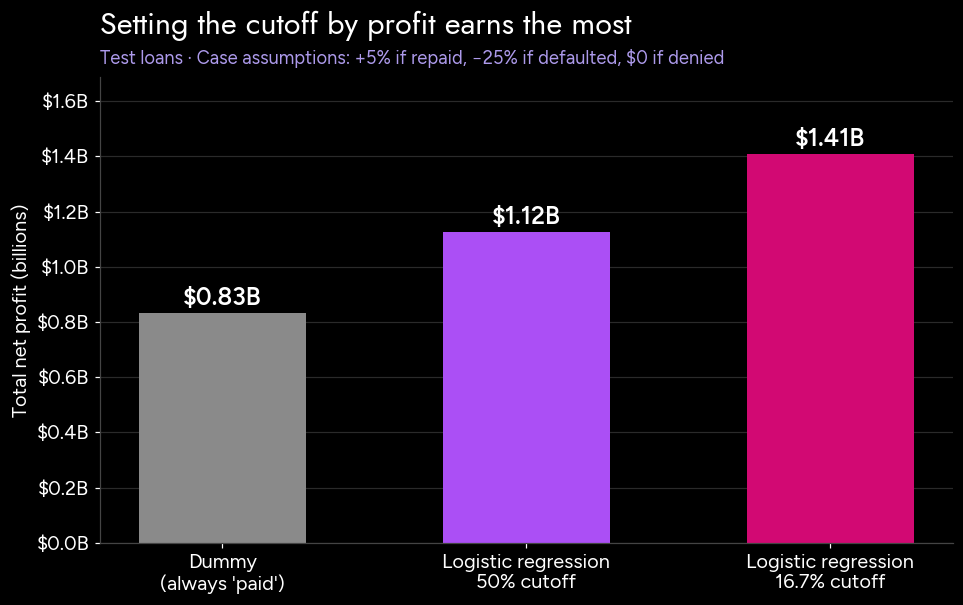

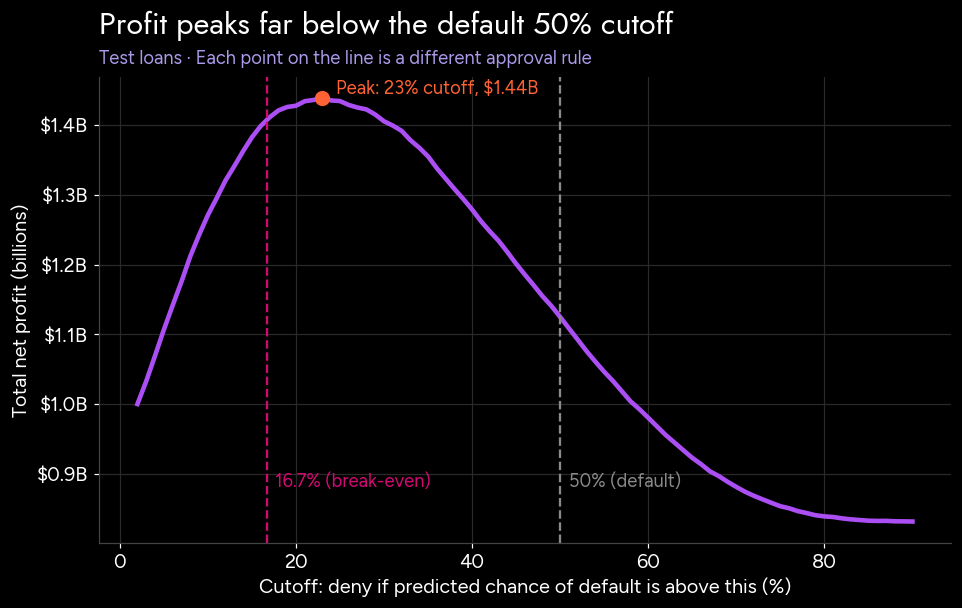

Best cutoff on test data: 0.23


In [ ]:
def profit(p, cut):
    approve = p < cut  # approve loans the model sees as lower risk
    gain = (0.05 * d_test[approve & (y_test == 0)]).sum()  # +5% on good loans approved
    loss = (0.25 * d_test[approve & (y_test == 1)]).sum()  # -25% on bad loans approved
    return gain - loss

prof = {name: profit(pte, cut) for name, (_, pte, cut) in models.items()}
for name, v in prof.items():
    print(f"{name.replace(chr(10), ' '):<38} ${v:,.0f}")

# --- Chart: total profit by decision rule ---
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(list(prof.keys()), [v / 1e9 for v in prof.values()], color=[GREY, PURPLE, MAGENTA], width=0.55)
for b, v in zip(bars, prof.values()):
    ax.text(b.get_x() + b.get_width() / 2, v / 1e9 + 0.03, f"${v / 1e9:.2f}B", ha="center", fontsize=16, fontfamily=BOLD)
ax.set_ylabel("Total net profit (billions)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:.1f}B"))
ax.set_ylim(0, max(prof.values()) / 1e9 * 1.2)
ax.grid(axis="x", visible=False)
title(ax, "Setting the cutoff by profit earns the most", "Test loans · Case assumptions: +5% if repaid, −25% if defaulted, $0 if denied")
plt.savefig("charts/3_profit_by_model.png")
plt.show()

# --- Chart: profit at every cutoff (the "re-tweak" step) ---
cuts = np.linspace(0.02, 0.9, 89)
curve = np.array([profit(p_test, c) for c in cuts]) / 1e9
best = cuts[curve.argmax()]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(cuts * 100, curve, color=PURPLE, linewidth=3)
for c, lab, col in [(CUTOFF, "16.7% (break-even)", MAGENTA), (0.5, "50% (default)", GREY)]:
    ax.axvline(c * 100, color=col, linestyle="--", linewidth=1.5)
    ax.text(c * 100 + 1, curve.min() + 0.05, lab, color=col, fontsize=12)
ax.scatter([best * 100], [curve.max()], color=CORAL, s=80, zorder=5)
ax.text(best * 100 + 1.5, curve.max(), f"Peak: {best:.0%} cutoff, ${curve.max():.2f}B", color=CORAL, fontsize=12, va="bottom")
ax.set_xlabel("Cutoff: deny if predicted chance of default is above this (%)")
ax.set_ylabel("Total net profit (billions)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:.1f}B"))
title(ax, "Profit peaks far below the default 50% cutoff", "Test loans · Each point on the line is a different approval rule")
plt.savefig("charts/4_profit_by_cutoff.png")
plt.show()
print("Best cutoff on test data:", round(best, 3))

Term                   -2.44
UrbanRural_Undefined   -0.86
StateMatch             -0.83
NAICS_Sector_21        -0.80
LowDoc_Y               -0.74
NAICS_Sector_62        -0.50
RevLineCr_Y            -0.43
NAICS_Sector_52         0.29
NAICS_Sector_Unknown    0.33
SBA_Portion             0.33
NAICS_Sector_72         0.35
LowDoc_Unknown          0.37
NAICS_Sector_53         0.44
Recession               0.61
dtype: float64

States with highest / lowest risk weights:
{'State_VT': -0.81, 'State_MT': -0.74, 'State_ME': -0.71} {'State_CA': 0.58, 'State_FL': 0.6, 'State_GA': 0.7}


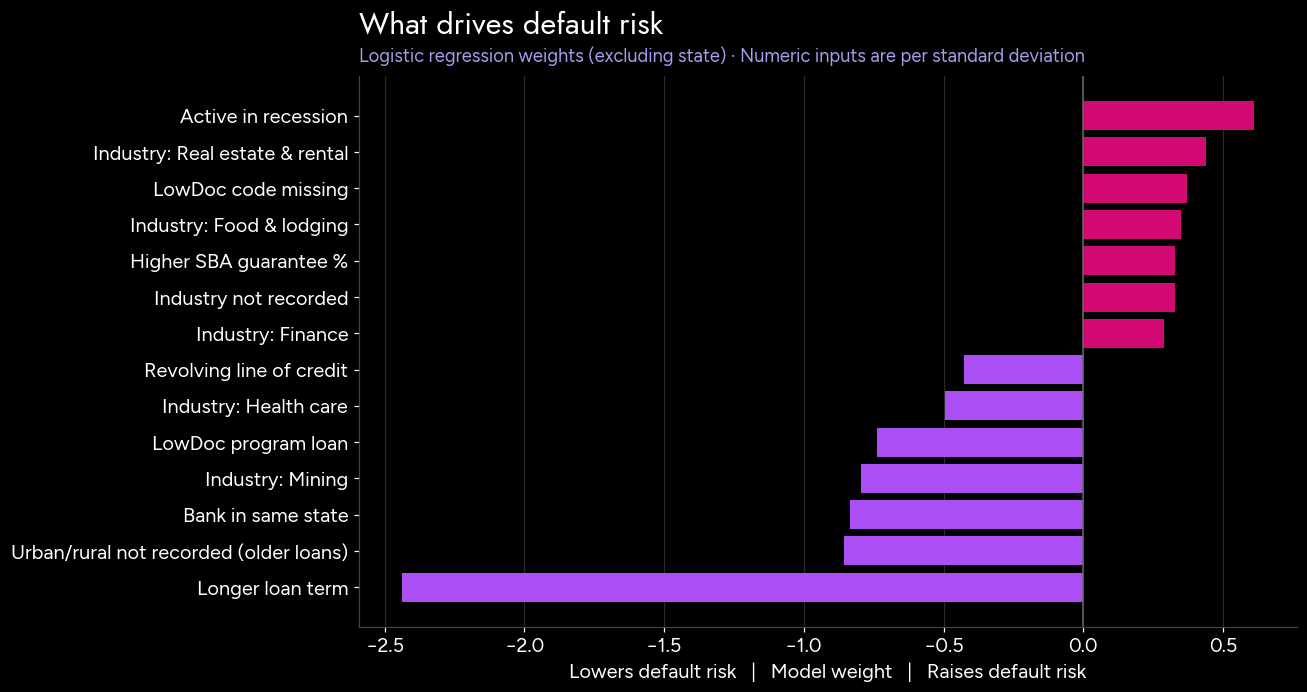

In [ ]:
SECTORS = {"11": "Agriculture", "21": "Mining", "22": "Utilities", "23": "Construction", "31": "Manufacturing",
           "42": "Wholesale", "44": "Retail", "48": "Transportation", "51": "Information", "52": "Finance",
           "53": "Real estate & rental", "54": "Professional services", "55": "Management", "56": "Admin & support",
           "61": "Education", "62": "Health care", "71": "Arts & recreation", "72": "Food & lodging",
           "81": "Other services", "92": "Public admin"}

def nice(col):  # turns column names into readable labels
    names = {"Term": "Longer loan term", "NoEmp": "More employees", "log_GrAppv": "Larger loan",
             "SBA_Portion": "Higher SBA guarantee %", "RealEstate": "Real-estate backed", "Recession": "Active in recession",
             "Franchise": "Franchise", "StateMatch": "Bank in same state", "UrbanRural_Undefined": "Urban/rural not recorded (older loans)",
             "LowDoc_Y": "LowDoc program loan", "LowDoc_Unknown": "LowDoc code missing", "RevLineCr_Y": "Revolving line of credit",
             "RevLineCr_Unknown": "Credit-line code missing", "NewExist_New": "New business", "NewExist_Unknown": "Business age unknown",
             "UrbanRural_Urban": "Urban business"}
    if col in names: return names[col]
    if col == "NAICS_Sector_Unknown": return "Industry not recorded"
    if col.startswith("NAICS_Sector_"): return "Industry: " + SECTORS.get(col[-2:], col[-2:])
    if col.startswith("State_"): return "State: " + col[6:]
    return col.replace("_", ": ")

coefs = pd.Series(model.coef_[0], index=X.columns)
coefs = coefs[~coefs.index.str.startswith("State_")].sort_values()  # states shown separately so the chart stays readable
top = pd.concat([coefs.head(7), coefs.tail(7)])  # 7 that lower risk most, 7 that raise it most
print(top.round(2))

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh([nice(c) for c in top.index], top.values, color=[PURPLE if v < 0 else MAGENTA for v in top.values])
ax.axvline(0, color="#666666", linewidth=1)
ax.set_xlabel("Lowers default risk   |   Model weight   |   Raises default risk")
ax.grid(axis="y", visible=False)
title(ax, "What drives default risk", "Logistic regression weights (excluding state) · Numeric inputs are per standard deviation")
print("\nStates with highest / lowest risk weights:")
states = pd.Series(model.coef_[0], index=X.columns).filter(like="State_").sort_values()
print(states.head(3).round(2).to_dict(), states.tail(3).round(2).to_dict())
plt.savefig("charts/5_risk_factors.png")
plt.show()

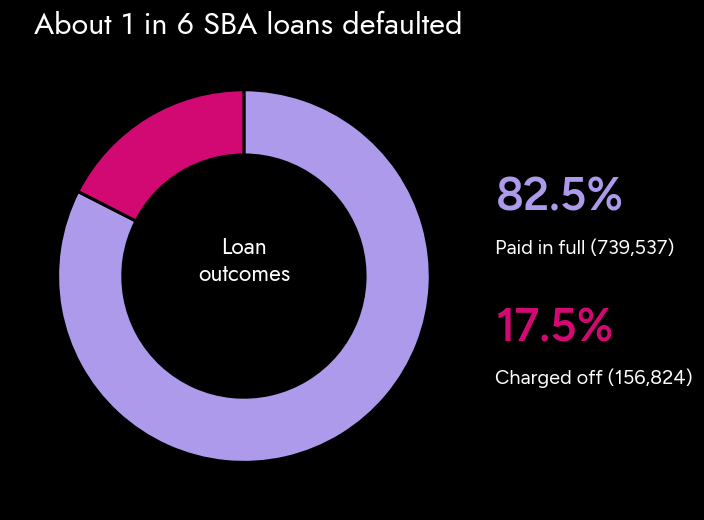

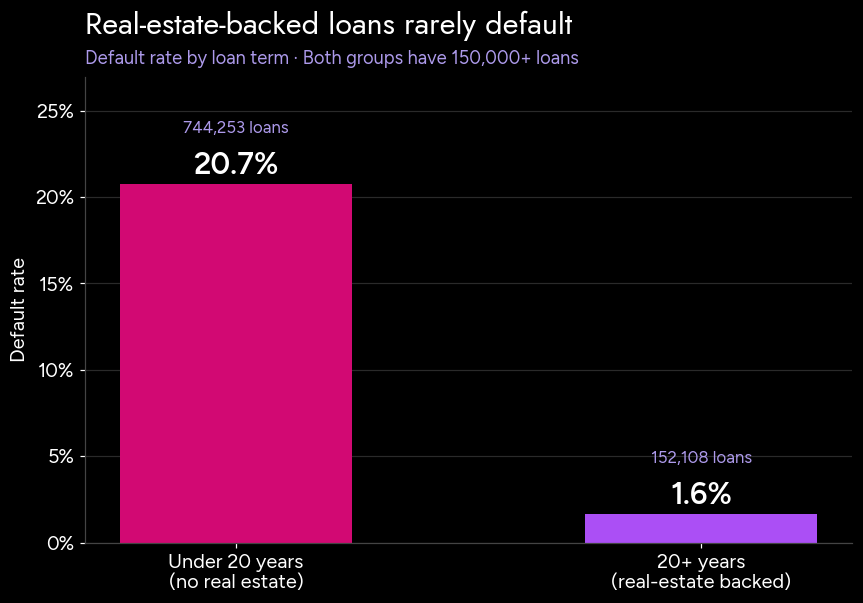

In [ ]:
# --- Required chart: loan status distribution ---
counts = df["Default"].value_counts().sort_index()
pct = counts / counts.sum()
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.pie(counts, colors=[LAVENDER, MAGENTA], startangle=90, counterclock=False,
       wedgeprops={"width": 0.35, "edgecolor": BLACK, "linewidth": 2})
ax.text(0, 0.08, "Loan\noutcomes", ha="center", va="center", fontsize=15, fontfamily=TITLE)
ax.text(1.35, 0.35, f"{pct[0]:.1%}", fontsize=30, color=LAVENDER, fontfamily=BOLD)
ax.text(1.35, 0.12, f"Paid in full ({counts[0]:,})", fontsize=13)
ax.text(1.35, -0.35, f"{pct[1]:.1%}", fontsize=30, color=MAGENTA, fontfamily=BOLD)
ax.text(1.35, -0.58, f"Charged off ({counts[1]:,})", fontsize=13)
ax.set_title("About 1 in 6 SBA loans defaulted", loc="left", fontfamily=TITLE, fontsize=20, x=0.05)
plt.savefig("charts/6_loan_status.png")
plt.show()

# --- Required chart: one meaningful comparison ---
comp = df.groupby("RealEstate")["Default"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(["Under 20 years\n(no real estate)", "20+ years\n(real-estate backed)"], comp["mean"] * 100,
              color=[MAGENTA, PURPLE], width=0.5)
for b, (rate, n) in zip(bars, comp.values):
    ax.text(b.get_x() + b.get_width() / 2, rate * 100 + 0.6, f"{rate:.1%}", ha="center", fontsize=20, fontfamily=BOLD)
    ax.text(b.get_x() + b.get_width() / 2, rate * 100 + 3, f"{int(n):,} loans", ha="center", fontsize=11, color=LAVENDER)
ax.set_ylabel("Default rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylim(0, comp["mean"].max() * 130)
ax.grid(axis="x", visible=False)
title(ax, "Real-estate-backed loans rarely default", "Default rate by loan term · Both groups have 150,000+ loans")
plt.savefig("charts/7_real_estate_comparison.png")
plt.show()

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("slide_charts", "zip", "charts")  # bundle all 7 chart images
files.download("slide_charts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>